# IMPORTING THE REQUIRE LIBARERY


In [330]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Data reading

In [331]:
df = pd.read_excel("/content/Processed_Flipdata.xlsx")

# Data Analysis

In [332]:
df.head()

,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999


In [333]:
df.shape

(541, 12)

In [334]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


# Checking duplicate


In [335]:
df.duplicated().sum()

np.int64(0)

# Removing unecessary columns

In [336]:
df.drop(["Unnamed: 0"], axis=1, inplace=True)

In [337]:
df.columns.tolist()

['Model',
 'Colour',
 'Memory',
 'RAM',
 'Battery_',
 'Rear Camera',
 'Front Camera',
 'AI Lens',
 'Mobile Height',
 'Processor_',
 'Prize']

# Preprocessing the data

In [338]:
# Rename the Target column
df.rename(columns={"Prize": "Price"}, inplace=True)

In [339]:
# Correcting the data type of the columns by removing 'MP' and converting to int
df['Front Camera'] = df['Front Camera'].str.replace('MP', '').astype(int)
df['Rear Camera'] = df['Rear Camera'].str.replace('MP', '').astype(int)

In [340]:
df

,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Price
0,Infinix SMART 7,Night Black,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,Infinix SMART 7,Azure Blue,64,4,6000,13,5,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,MOTOROLA G32,Mineral Gray,128,8,5000,50,16,0,16.64,Qualcomm Snapdragon 680,11999
3,POCO C50,Royal Blue,32,2,5000,8,5,0,16.56,Mediatek Helio A22,5649
4,Infinix HOT 30i,Marigold,128,8,5000,50,5,1,16.76,G37,8999
...,...,...,...,...,...,...,...,...,...,...,...
536,SAMSUNG Galaxy S23 5G,Cream,256,8,3900,50,12,0,15.49,Qualcomm Snapdragon 8 Gen 2,79999
537,LAVA Z21,Cyan,32,2,3100,5,2,0,12.70,Octa Core,5998
538,Tecno Spark 8T,Turquoise Cyan,64,4,5000,50,8,0,16.76,MediaTek Helio G35,9990
539,SAMSUNG Galaxy A54 5G,Awesome Lime,128,8,5000,50,32,0,16.26,"Exynos 1380, Octa Core",38999


In [341]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Model          541 non-null    object 
 1   Colour         541 non-null    object 
 2   Memory         541 non-null    int64  
 3   RAM            541 non-null    int64  
 4   Battery_       541 non-null    int64  
 5   Rear Camera    541 non-null    int64  
 6   Front Camera   541 non-null    int64  
 7   AI Lens        541 non-null    int64  
 8   Mobile Height  541 non-null    float64
 9   Processor_     541 non-null    object 
 10  Price          541 non-null    int64  
dtypes: float64(1), int64(7), object(3)
memory usage: 46.6+ KB


# Exploratory data analysis

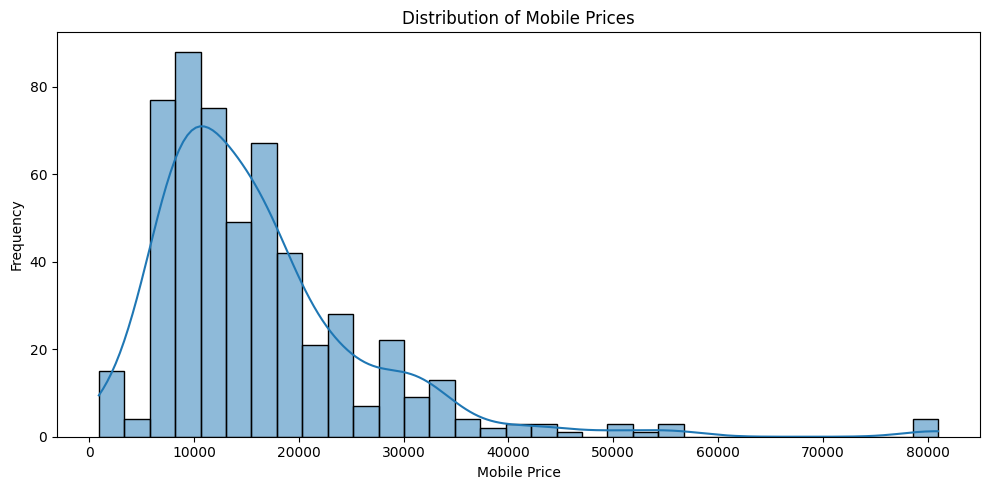

In [342]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df["Price"],

    kde=True
)

plt.title("Distribution of Mobile Prices")
plt.xlabel("Mobile Price")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

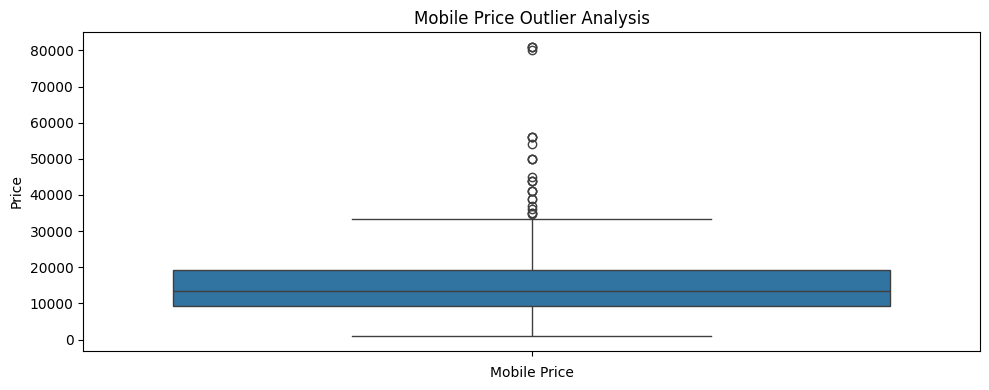

In [343]:
plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df['Price'],

)

plt.title("Mobile Price Outlier Analysis")
plt.xlabel("Mobile Price")

plt.tight_layout()
plt.show()

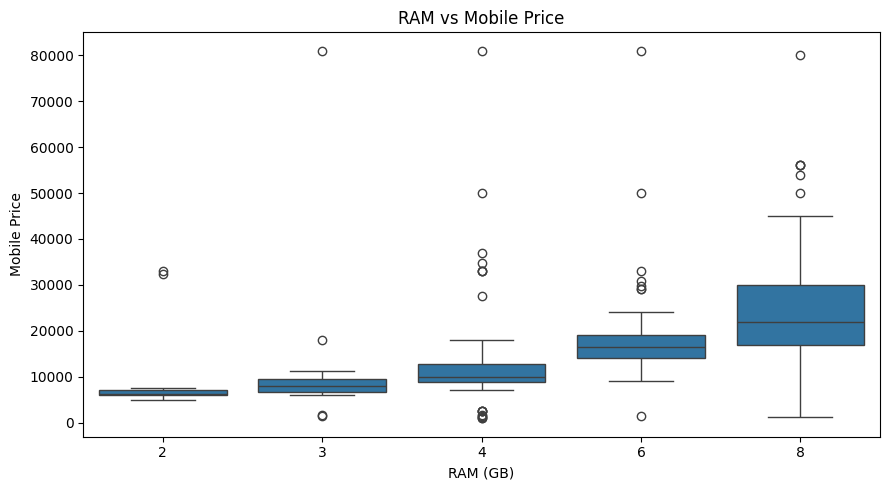

In [344]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=df["RAM"],
    y=df["Price"]
)

plt.title("RAM vs Mobile Price")
plt.xlabel("RAM (GB)")
plt.ylabel("Mobile Price")

plt.tight_layout()
plt.show()

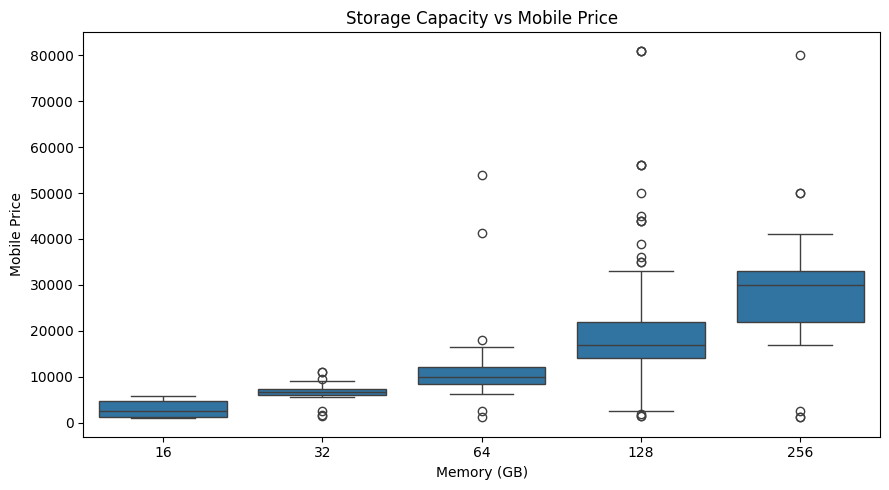

In [345]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x=df["Memory"],
    y=df["Price"]
)

plt.title("Storage Capacity vs Mobile Price")
plt.xlabel("Memory (GB)")
plt.ylabel("Mobile Price")

plt.tight_layout()
plt.show()

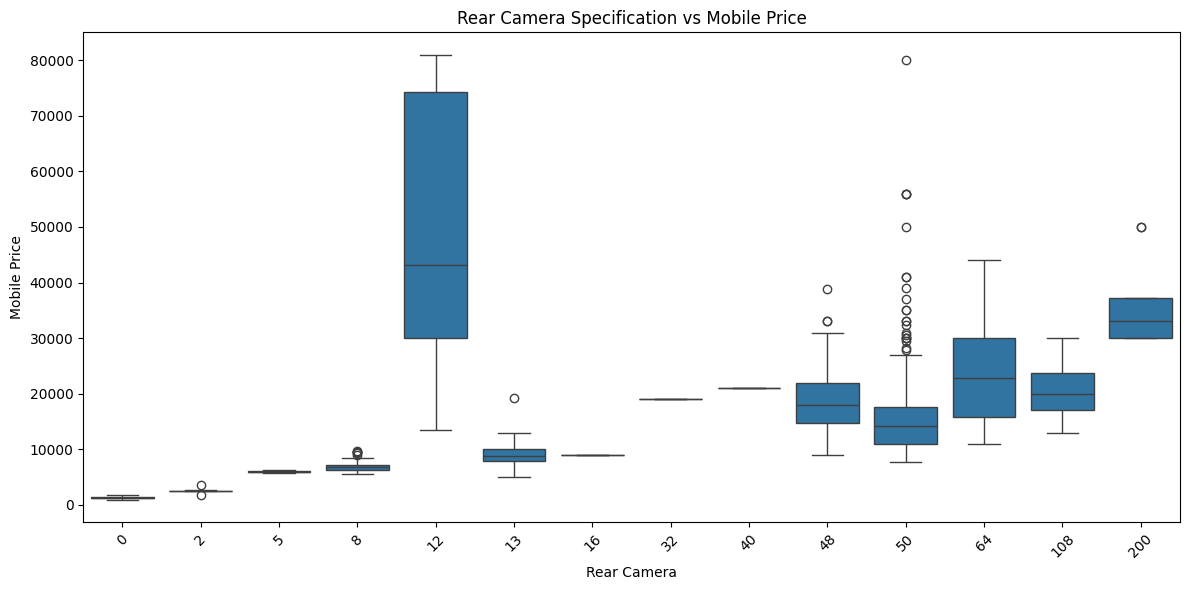

In [346]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x=df["Rear Camera"],
    y=df["Price"]
)

plt.title("Rear Camera Specification vs Mobile Price")
plt.xlabel("Rear Camera")
plt.ylabel("Mobile Price")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

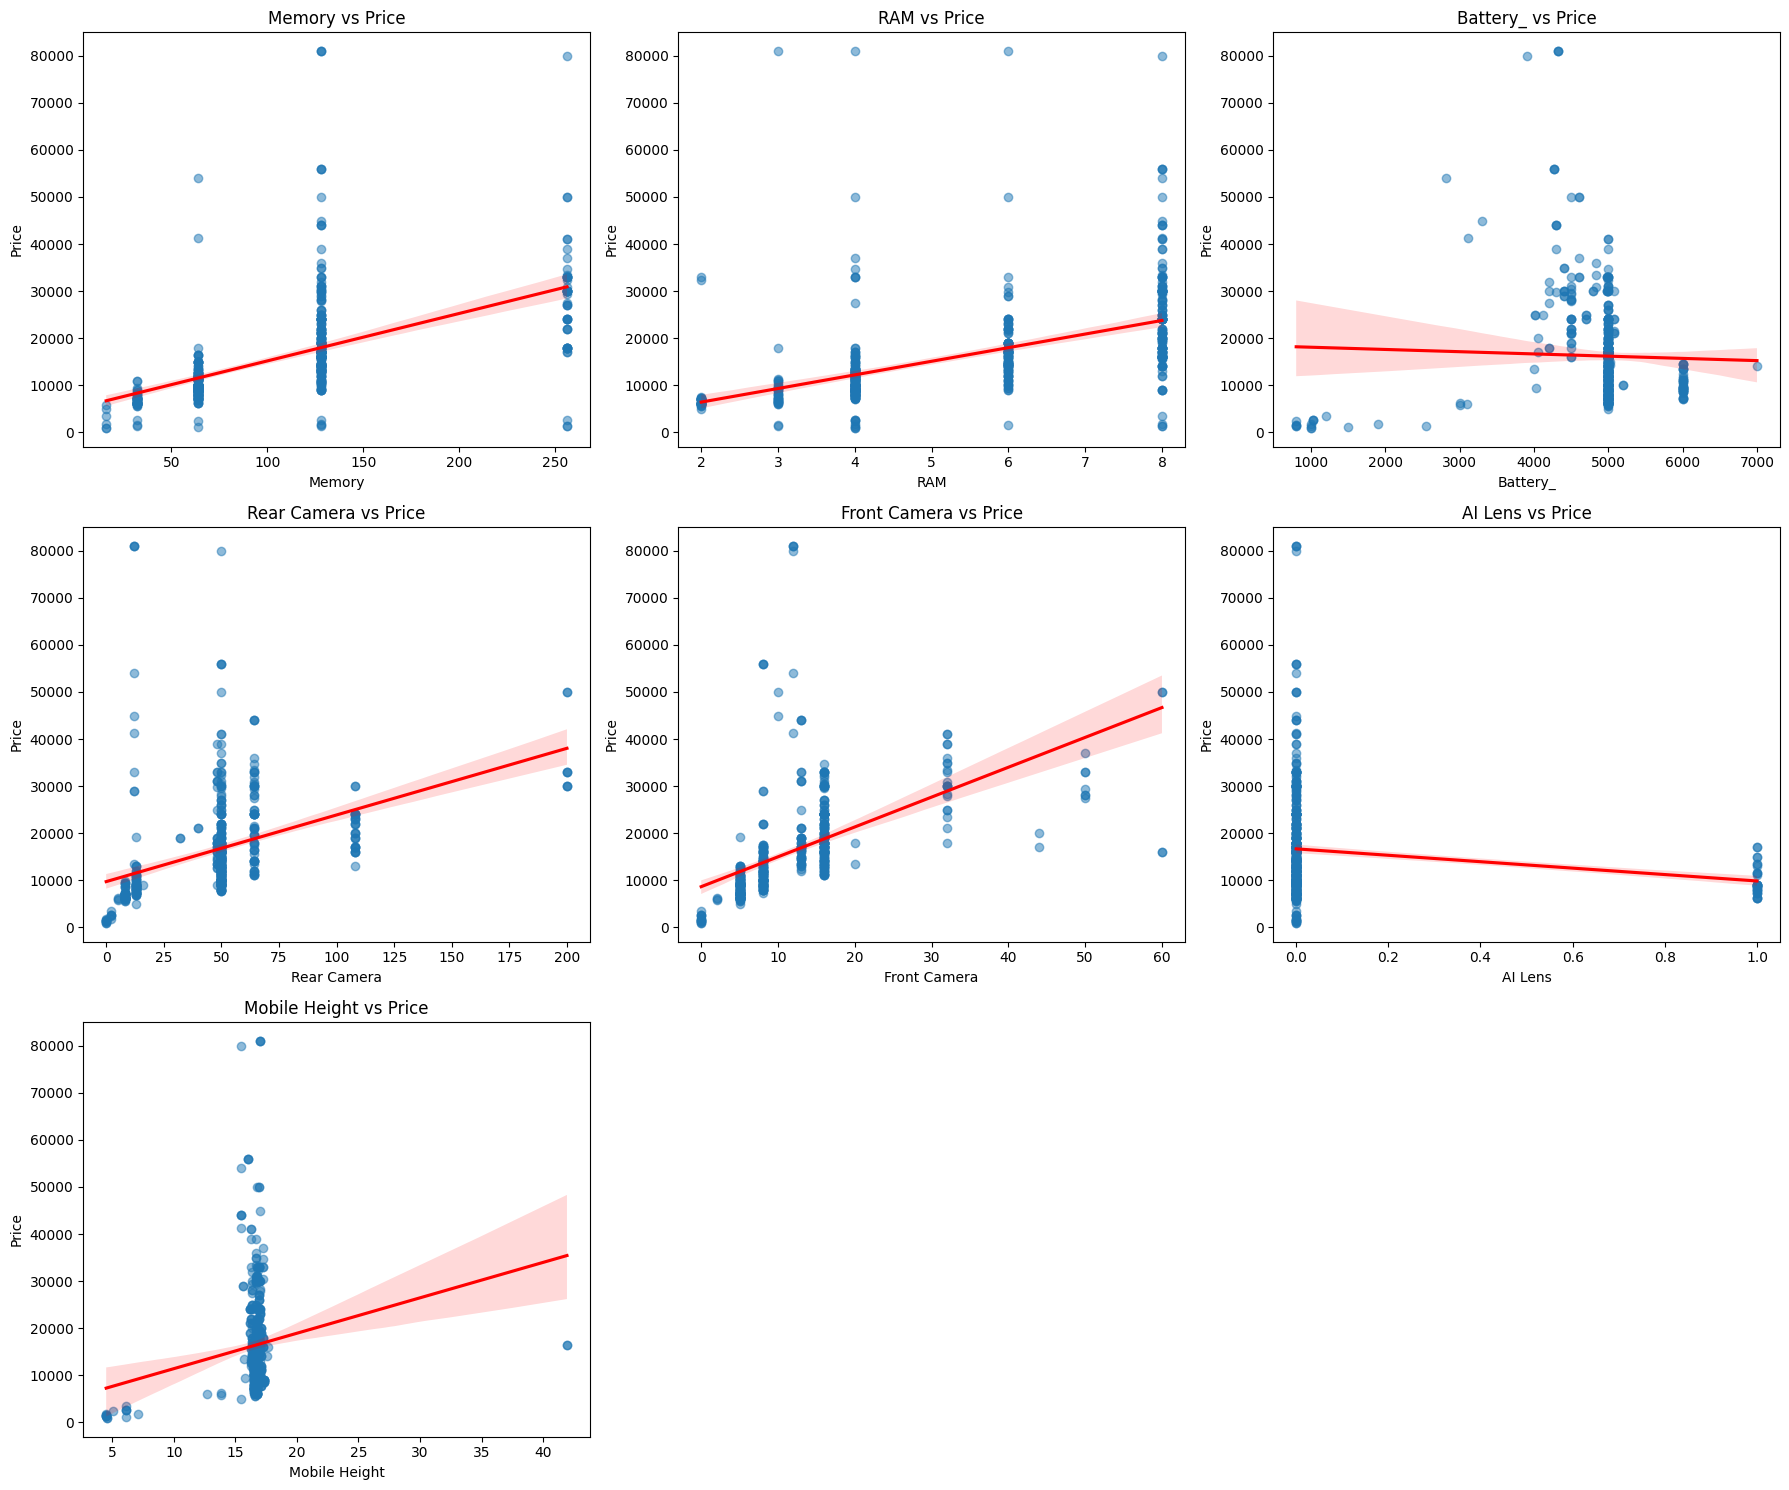

In [347]:

import math

# Select numerical columns only
numeric_cols = df.select_dtypes(include=np.number).columns

# Exclude target column
features = [col for col in numeric_cols if col != 'Price']

# Create subplots
n_cols = 3
n_rows = math.ceil(len(features) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 5 * n_rows)
)

axes = np.array(axes).flatten()

# Plot all features
for i, col in enumerate(features):
    sns.regplot(
        data=df,
        x=col,
        y='Price',
        ax=axes[i],
        scatter_kws={'alpha': 0.5},
        line_kws={'color': 'red'}
    )

    axes[i].set_title(f'{col} vs Price')

# Remove empty subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

# Checking the Outlier through the help of the box plot


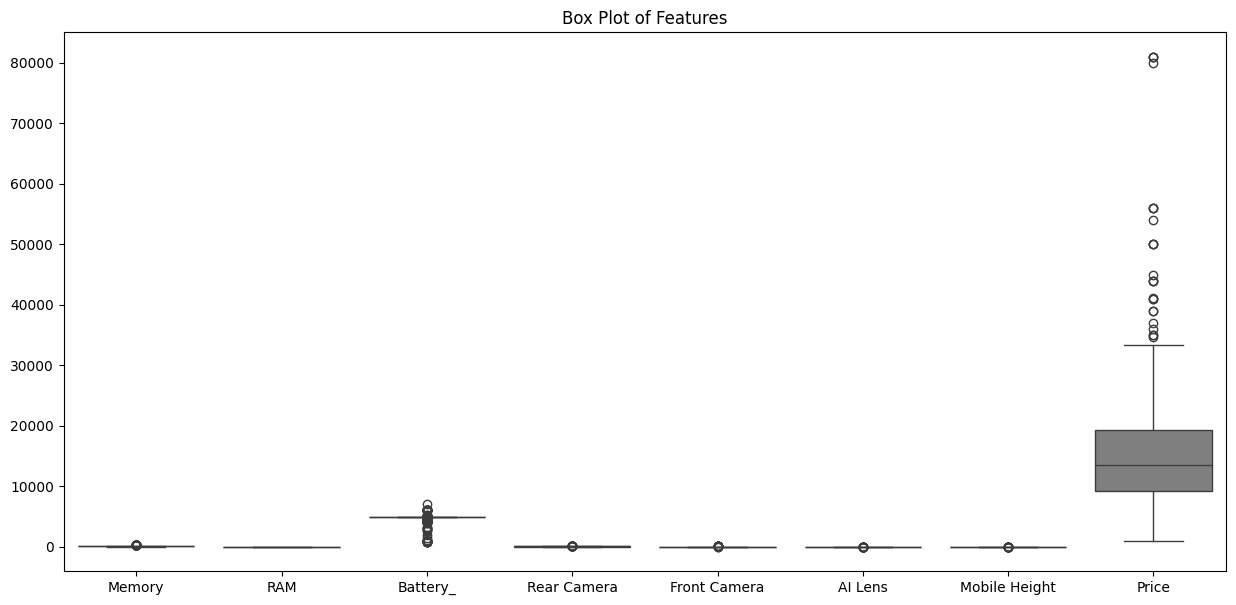

In [348]:
plt.figure(figsize=(15, 7
)
)
sns.boxplot(df)
plt.title("Box Plot of Features")
plt.show()


# Major outlier are seen in the battery and Price


In [349]:
# checking the outliers are actually outlier or its  our data  for the price column
Q1 = df['Price'].quantile(0.25)
Q3 = df['Price'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

outliers = df[
    (df['Price'] < lower_limit) |
    (df['Price'] > upper_limit)
]

print("Price outliers:", len(outliers))
print("Total rows:", len(df))

Q1: 9290.0
Q3: 19280.0
IQR: 9990.0
Lower limit: -5695.0
Upper limit: 34265.0
Price outliers: 25
Total rows: 541


In [350]:
display(outliers[['Model', 'Price']].sort_values('Price'))

,Model,Price
522,IQOO Neo 7 5G,34688
305,MOTOROLA Edge 30 Fusion,34999
419,MOTOROLA Edge 30 Fusion,34999
496,vivo V25 Pro 5G,35999
396,vivo V27 5G,36999
455,OnePlus 8,38920
539,SAMSUNG Galaxy A54 5G,38999
465,SAMSUNG Galaxy A54 5G,40999
515,SAMSUNG Galaxy A54 5G,40999
474,APPLE iPhone 11,41199


In [351]:
# checking the outliers are actually outlier or its  our data  for the price column
Q1b = df['Battery_'].quantile(0.25)
Q3b = df['Battery_'].quantile(0.75)

IQRb = Q3b - Q1b

lower_limit_b = Q1b - 1.5 * IQRb
upper_limit_b = Q3b + 1.5 * IQRb

print("Q1:", Q1b)
print("Q3:", Q3b)
print("IQR:", IQRb)
print("Lower limit:", lower_limit_b)
print("Upper limit:", upper_limit_b)

outliersb = df[
    (df['Battery_'] < lower_limit_b) |
    (df['Battery_'] > upper_limit_b)
]

print("battery  outliers:", len(outliers))
print("Total rows:", len(df))

Q1: 5000.0
Q3: 5000.0
IQR: 0.0
Lower limit: 5000.0
Upper limit: 5000.0
battery  outliers: 25
Total rows: 541


In [352]:
display(outliersb[['Model', 'Battery_']].sort_values('Battery_'))

,Model,Battery_
118,micromax 1,800
98,Micromax IN 2C,800
155,micromax 2,800
152,micromax 3,800
182,micromax1,800
...,...,...
0,Infinix SMART 7,6000
37,SAMSUNG Galaxy F13,6000
36,SAMSUNG Galaxy F13,6000
508,realme Narzo 50A,6000


# Since the outlier are the actual price and the actual battery of our data it not said to be an outlier that why we dont remove the oultier from our data


# CONVERTING THE CATEGORICAL COLUMN TO THE NUMERIC FOR THE  MACHINE UNDERSTANDING


In [353]:
df.shape

(541, 11)

# Features Selection  using heatmap



In [354]:
from sklearn.preprocessing import LabelEncoder

# Label Encoding safely
le = LabelEncoder()
df['Colour']= le.fit_transform(df['Colour'])
df['Model'] = le.fit_transform(df['Model'])
df[ 'Processor_'] = le.fit_transform(df[ 'Processor_'])
print(df.shape)
df.head()

(541, 11)


,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Price
0,23,159,64,4,6000,13,5,1,16.76,113,7299
1,23,20,64,4,6000,13,5,1,16.76,113,7299
2,37,149,128,8,5000,50,16,0,16.64,75,11999
3,69,201,32,2,5000,8,5,0,16.56,56,5649
4,12,130,128,8,5000,50,5,1,16.76,14,8999


In [355]:
df.shape

(541, 11)

In [356]:
#correlation

df_corr = new_df.corr()

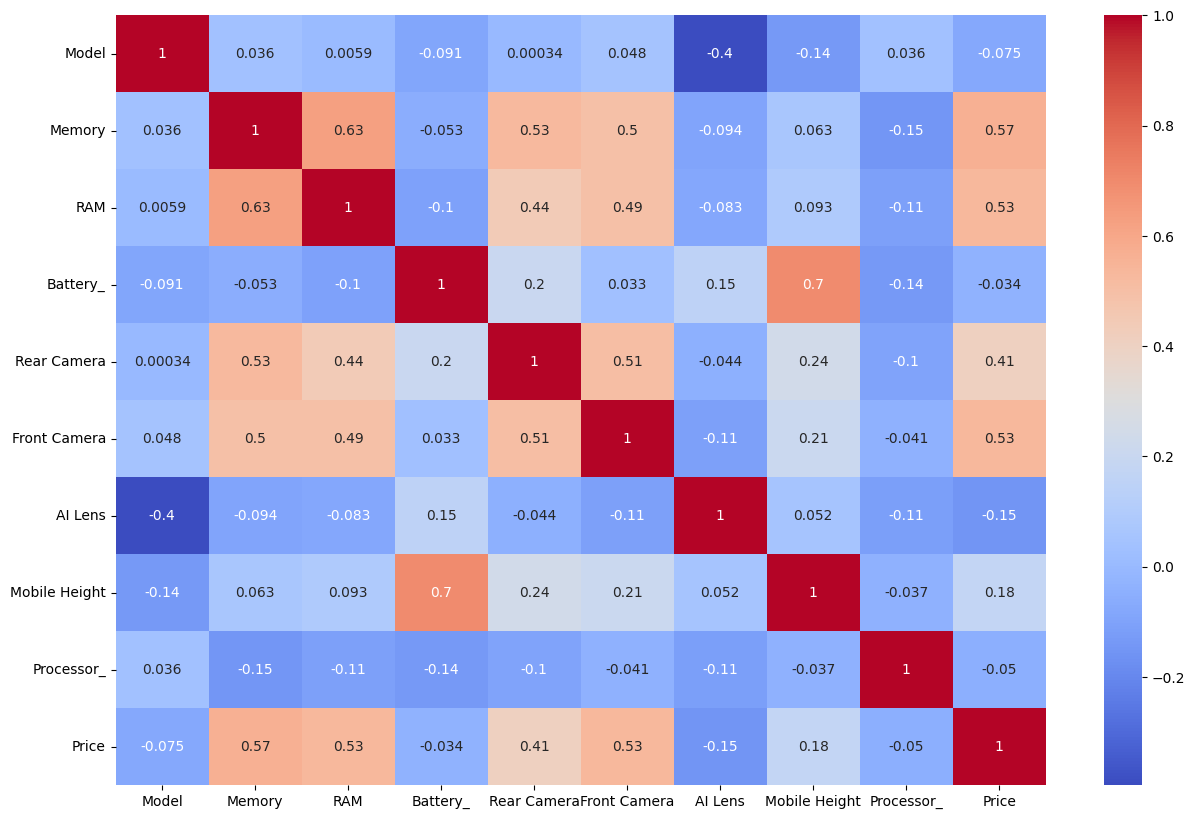

In [357]:
# Heatmap
plt.figure(figsize=(15,10))
sns.heatmap(df_corr, annot=True,cmap = 'coolwarm')
plt.show()

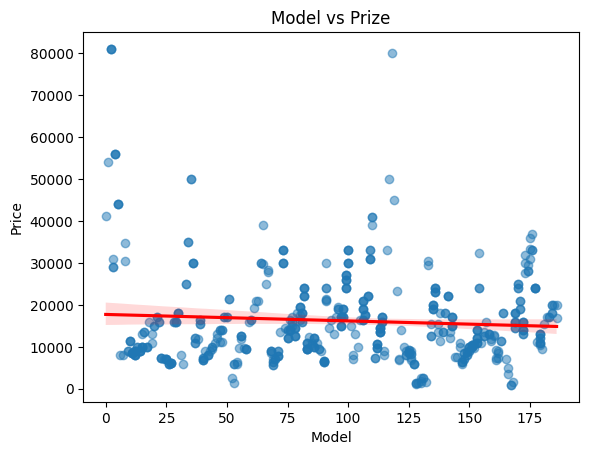

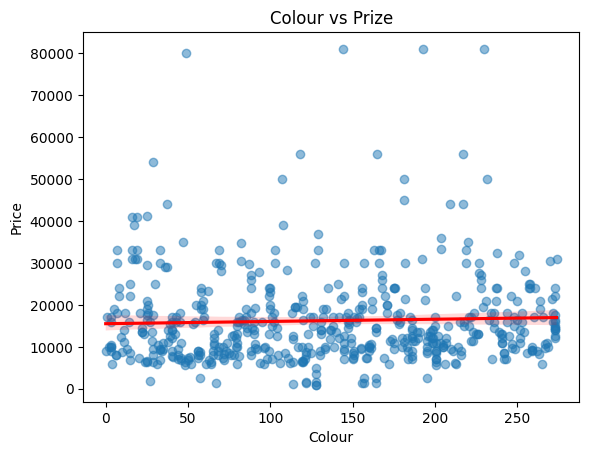

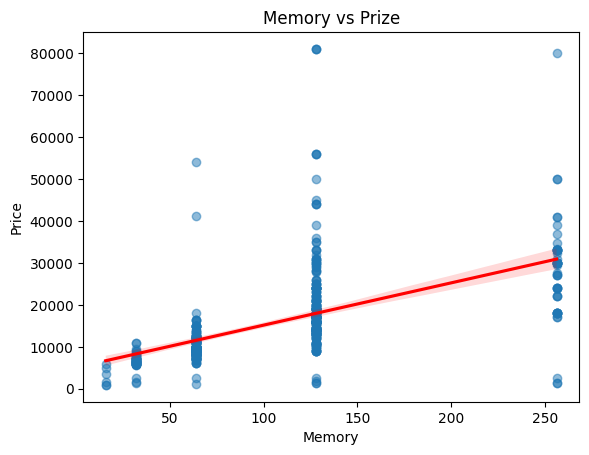

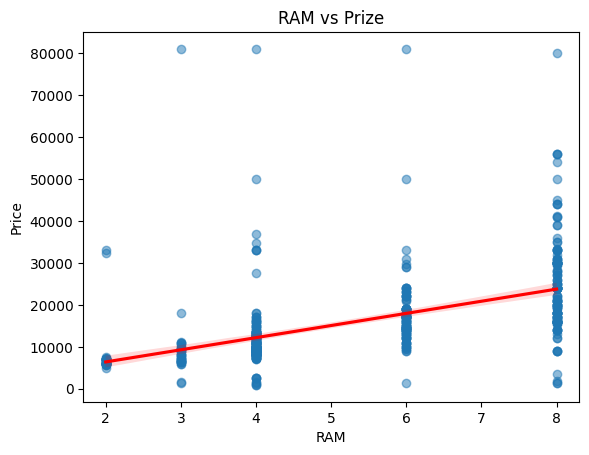

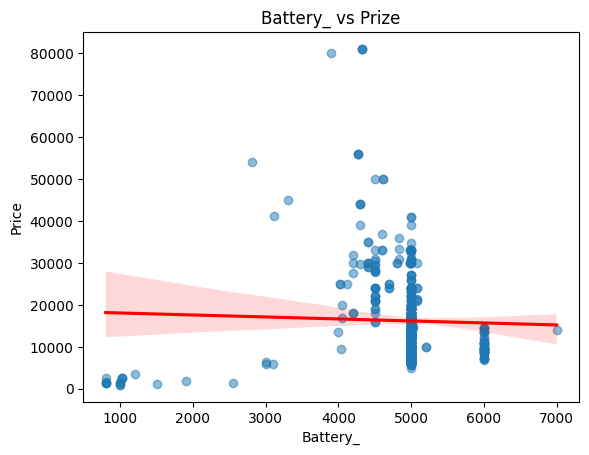

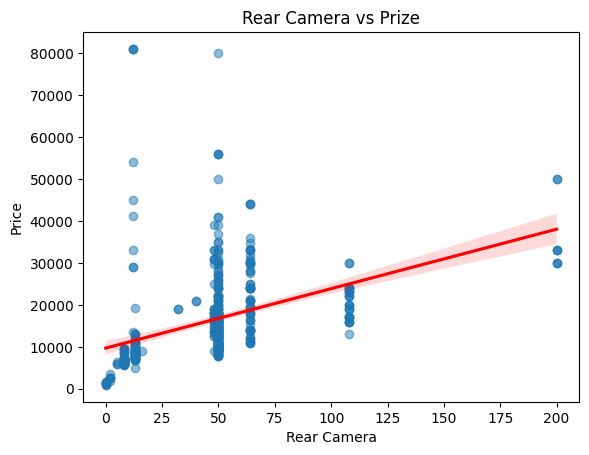

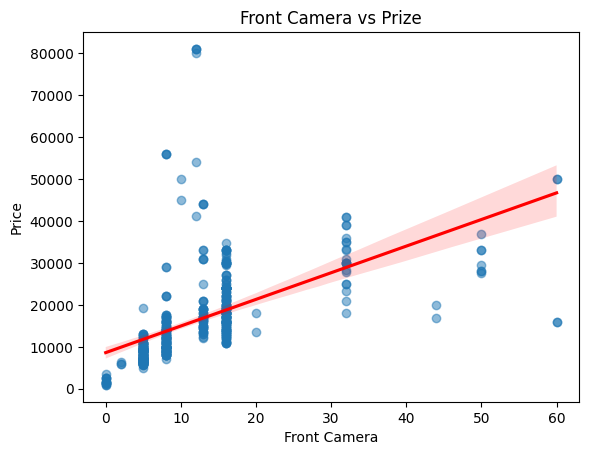

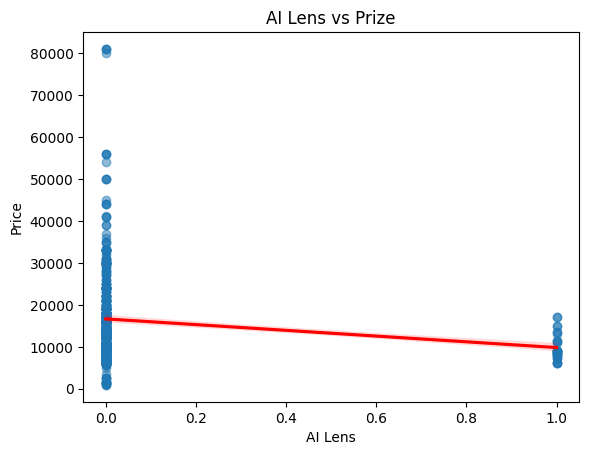

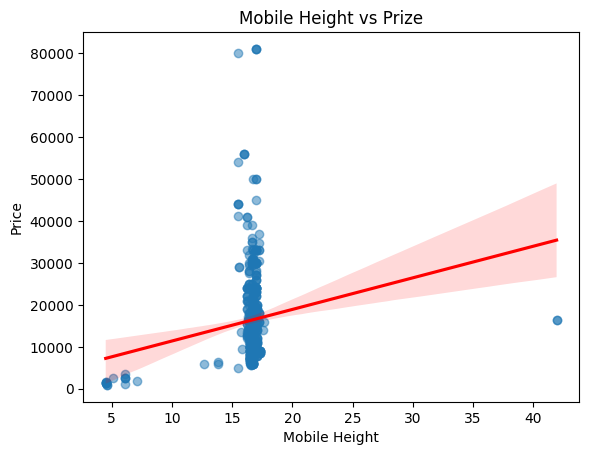

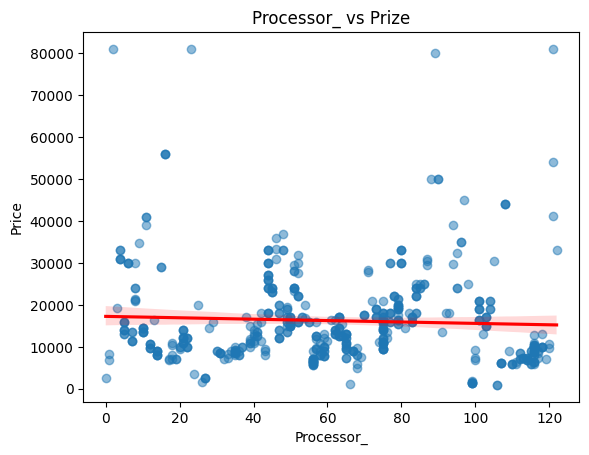

In [358]:
for col in df.columns:
    if col != 'Price':
        sns.regplot(
            data=df,
            x=col,
            y='Price',
            scatter_kws={'alpha': 0.5},
            line_kws={'color': 'red'}
        )
        plt.title(f'{col} vs Prize')
        plt.show()

In [359]:
df.columns

Index(['Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera',
       'Front Camera', 'AI Lens', 'Mobile Height', 'Processor_', 'Price'],
      dtype='object')

In [360]:
# feature selection
x  = df[['Model', 'Colour', 'Memory', 'RAM', 'Battery_', 'Rear Camera',
       'Front Camera', 'Processor_']]
y = df['Price']

# Spliting the data into the train and test data set



In [361]:
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest = train_test_split(x,y,test_size=0.2,random_state=42)

# Scaling the data

In [362]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()


xtrain_sc = sc.fit_transform(xtrain)
xtest_sc = sc.transform(xtest)

# Model Selection And Implementation

In [363]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [364]:
lr = LinearRegression()
lr.fit(xtrain_sc,ytrain)
y_pred_lr = lr.predict(xtest_sc)


In [365]:
mae_lr = mean_squared_error(ytest, y_pred_lr)

print("Mean Absolute Error (MAE):")
print("Linear Regression:", mae_lr)


Mean Absolute Error (MAE):
Linear Regression: 84177715.93925218


In [366]:
r2_score_lr = r2_score(ytest, y_pred_lr)
print("R-squared Score:")
print("Linear Regression:", r2_score_lr)


R-squared Score:
Linear Regression: 0.38925442043788305


In [367]:
from sklearn.ensemble import GradientBoostingRegressor
gr =GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42
)
gr.fit(xtrain_sc,ytrain)
y_pred_gr = gr.predict(xtest_sc)

In [368]:
mse_lr = mean_squared_error(ytest, y_pred_gr)

print("Mean Absolute Error (MAE):")
print("GradientboostingRegressor:", mse_lr)

Mean Absolute Error (MAE):
GradientboostingRegressor: 19245405.62831604


In [369]:
r2_score_gr = r2_score(ytest, y_pred_gr)
print("R-squared Score:")
print("GradientboostingRegressor:", r2_score_gr)


R-squared Score:
GradientboostingRegressor: 0.8603662942950798


In [375]:
from pickle import dump
dump(gr,open('model_gr.pkl','wb'))
